# Method comparison -- in-silico detection and detection limit

Reads only `results/*.csv`; every pipeline / scenario written by `eval/build_results.sh <pipe>` shows up
on the next run. Methods on the x axis, evaluation scenario as grouped bars:

- `zero_shot`: no information from the held-out batch
- `adaptation`: half of the held-out batch's HC, cross-fitted -- mean-only shift for every method.
  CV has no adaptation (every batch is already in training).

Designs: in-silico sweep = `MethodComparison/sweep.py` (nb5), all held-out HC of each fold / batch;
detection limit = `3_detection_limit.ipynb`, half-boot of the held-out HC.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

parent_dir = str(Path.cwd().parent)
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)
from viz_style import FS_ANNOT_SM, apply_style
apply_style()

import _FinalModelingMethodImprovement.config as config

Q = 0.05
LOG2FC_SHOW = [0.0, 1.0, 2.0, 3.0, 5.0]
RATES = ['Precision', 'Recall', 'F1', 'FDR']
COUNTS = ['TP per sample', 'FP per sample', 'FN per sample']
METRICS = RATES + COUNTS
FIG_DIR = config.RESULTS_DIR / 'Figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

METHOD_ORDER = ['p0', 'p2', 'p3', 'autoencoder', 'pca', 'outsingle', 'peer']
NAMES = {'p0': 'p0 current', 'p2': 'p2 RUV', 'p3': 'p3 RUV + length/GC', **config.OUTLIER_ARMS}
COLORS = {'p0': '#000000', 'p2': '#0072B2', 'p3': '#D55E00', 'autoencoder': '#1B9E77',
          'pca': '#7570B3', 'outsingle': '#D95F02', 'peer': '#E7298A'}
SCENARIOS = ['zero_shot', 'adaptation']
HATCH = {'zero_shot': '', 'adaptation': '///'}
ALPHA = {'zero_shot': 1.0, 'adaptation': 0.45}
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 60)

In [2]:
def summarize(df, unit):
    """Pool tp/fp/fn/tn over folds (or batch x boot) per split x method x scenario x q x log2fc.
    Counts per sample = pooled count / pooled number of scored samples."""
    keys = ['split', 'method', 'scenario', 'q', 'log2fc']
    g = df.groupby(keys)[['tp', 'fp', 'fn', 'tn']].sum()
    n = df.groupby(keys + unit)['n_samples'].first().groupby(keys).sum()
    tp, fp, fn = g['tp'], g['fp'], g['fn']
    return pd.DataFrame({'Precision': tp / (tp + fp), 'Recall': tp / (tp + fn),
                         'F1': 2 * tp / (2 * tp + fp + fn), 'FDR': fp / (tp + fp),
                         'TP per sample': tp / n, 'FP per sample': fp / n, 'FN per sample': fn / n}).reset_index()


def methods_in(s):
    return [m for m in METHOD_ORDER if m in set(s['method'])] + sorted(set(s['method']) - set(METHOD_ORDER))


def tables(s, title):
    """One table per split x metric: methods as rows, (log2fc, scenario) as columns."""
    s = s[s['q'] == Q]
    for split, sub in s.groupby('split'):
        print(f'===== {title} | {split} | q={Q}')
        for m in METRICS:
            t = sub[sub['log2fc'].isin(LOG2FC_SHOW)].pivot_table(index='method', columns=['log2fc', 'scenario'], values=m)
            print(f'--- {m}')
            display(t.reindex(methods_in(sub)).rename(index=NAMES).round(3 if m in RATES else 1))


def bars(ax, sub, value, methods):
    w = 0.8 / len(SCENARIOS)
    for k, scen in enumerate(SCENARIOS):
        v = sub[sub['scenario'] == scen].set_index('method')[value].reindex(methods)
        x = np.arange(len(methods)) + (k - (len(SCENARIOS) - 1) / 2) * w
        ax.bar(x, v.values, width=w, color=[COLORS.get(m, '#888888') for m in methods],
               alpha=ALPHA[scen], hatch=HATCH[scen], edgecolor='black', lw=0.4,
               label=scen.replace('_', '-'))
    ax.set_xticks(np.arange(len(methods)))
    ax.set_xticklabels([NAMES.get(m, m) for m in methods], rotation=45, ha='right')


def figure(s, title, fname):
    """Per split: rows = metrics (rates on 0-1, counts per sample on a linear axis shared
    along the row), columns = log2fc; x axes shared down each column."""
    s = s[s['q'] == Q]
    for split, sp in s.groupby('split'):
        methods = methods_in(sp)
        fig, axes = plt.subplots(len(METRICS), len(LOG2FC_SHOW), sharex=True, sharey='row',
                                 figsize=(2.9 * len(LOG2FC_SHOW), 1.7 * len(METRICS)), squeeze=False,
                                 gridspec_kw=dict(hspace=0.08, wspace=0.08))
        for j, fc in enumerate(LOG2FC_SHOW):
            for i, m in enumerate(METRICS):
                ax = axes[i, j]
                bars(ax, sp[sp['log2fc'] == fc], m, methods)
                if m in RATES:
                    ax.set_ylim(0, 1)
                if m == 'FDR':
                    ax.axhline(Q, color='red', ls=':', lw=0.8)
                if i == 0:
                    ax.set_title(f'log2FC = {fc:g}' + (' (no signal)' if fc == 0 else ''))
                if j == 0:
                    ax.set_ylabel(m)
        for ax in axes[:-1].flat:
            ax.tick_params(labelbottom=False)
        for ax in axes[:, 1:].flat:
            ax.tick_params(labelleft=False)
        axes[0, -1].legend(frameon=False, fontsize=FS_ANNOT_SM, loc='upper left', bbox_to_anchor=(1.02, 1))
        fig.suptitle(f'{title}: {split}, q = {Q}', y=0.995)
        fig.savefig(FIG_DIR / f'{fname}_{split}.png', dpi=300, bbox_inches='tight')
        plt.show()

## In-silico detection (sweep design)

In [3]:
ins = summarize(pd.read_csv(config.INSILICO_CSV), unit=['fold'])
ins.to_csv(config.RESULTS_DIR / 'summary_insilico.csv', index=False)
print(ins.groupby(['split', 'method'])['scenario'].unique().to_string())
tables(ins, 'in-silico')

split  method     
cv     autoencoder                [zero_shot]
       outsingle                  [zero_shot]
       p0                         [zero_shot]
       p2                         [zero_shot]
       pca                        [zero_shot]
       peer                       [zero_shot]
lobo   autoencoder    [adaptation, zero_shot]
       outsingle      [adaptation, zero_shot]
       p0             [adaptation, zero_shot]
       p2             [adaptation, zero_shot]
       pca            [adaptation, zero_shot]
       peer           [adaptation, zero_shot]
===== in-silico | cv | q=0.05
--- Precision


log2fc,0.0,1.0,2.0,3.0,5.0
scenario,zero_shot,zero_shot,zero_shot,zero_shot,zero_shot
method,,,,,
p0 current,0.040,0.289,0.829,0.890,0.650
p2 RUV,0.041,0.148,0.667,0.795,0.853
OUTRIDER (AE),0.041,0.150,0.362,0.460,0.520
PCA,0.041,0.141,0.404,0.531,0.625
OutSingle,0.041,0.111,0.210,0.260,0.289
PEER,0.041,0.090,0.257,0.399,0.562


--- Recall


log2fc,0.0,1.0,2.0,3.0,5.0
scenario,zero_shot,zero_shot,zero_shot,zero_shot,zero_shot
method,,,,,
p0 current,0.003,0.029,0.388,0.670,0.872
p2 RUV,0.005,0.020,0.297,0.637,0.860
OUTRIDER (AE),0.040,0.164,0.521,0.761,0.920
PCA,0.024,0.090,0.385,0.649,0.933
OutSingle,0.096,0.280,0.619,0.834,0.991
PEER,0.025,0.057,0.213,0.434,0.896


--- F1


...

log2fc               0.0                  1.0                  2.0                  3.0                  5.0          
scenario      adaptation zero_shot adaptation zero_shot adaptation zero_shot adaptation zero_shot adaptation zero_shot
method                                                                                                                
p0 current           1.8       2.0       10.0       9.9      155.6     151.4      303.6     302.2      413.6     418.5
p2 RUV               5.8       6.1       11.0      10.2      125.5     126.9      301.2     300.8      422.5     425.7
OUTRIDER (AE)       53.0      32.9      111.9     110.7      275.4     288.0      382.0     397.8      458.0     465.5
PCA                 25.4      24.9       67.7      76.7      221.0     234.9      350.1     360.3      474.8     480.0
OutSingle           68.8      65.4      173.7     166.9      337.7     337.5      433.4     436.7      495.1     495.9
PEER                16.5      16.1       36.0      32.8      125.6     120.2      243.3     240.3      455.3     464.0

--- FP per sample


log2fc               0.0                  1.0                  2.0                  3.0                  5.0          
scenario      adaptation zero_shot adaptation zero_shot adaptation zero_shot adaptation zero_shot adaptation zero_shot
method                                                                                                                
p0 current          40.4      44.7       44.0      48.0       50.2      54.2       46.5      52.5      158.1     170.1
p2 RUV             137.6     147.1      160.1     171.9      182.5     198.7      184.7     200.7      132.4     146.0
OUTRIDER (AE)     1198.5     767.3     1213.2     769.8     1248.3     764.7     1276.0     750.9     1327.3     724.7
PCA                588.2     577.8      576.3     555.0      600.6     568.9      612.0     568.4      613.0     553.0
OutSingle         1623.6    1534.3     1626.1    1535.5     1667.0    1578.0     1692.7    1603.5     1727.7    1640.4
PEER               389.9     379.6      388.1     378.1      414.0     404.8      439.3     430.7      468.6     460.5

--- FN per sample


log2fc               0.0                  1.0                  2.0                  3.0                  5.0          
scenario      adaptation zero_shot adaptation zero_shot adaptation zero_shot adaptation zero_shot adaptation zero_shot
method                                                                                                                
p0 current         498.2     498.0      490.0     490.1      344.4     348.6      196.4     197.8       86.4      81.5
p2 RUV             494.2     493.9      489.0     489.8      374.5     373.1      198.8     199.2       77.5      74.3
OUTRIDER (AE)      447.0     467.1      388.1     389.3      224.6     212.0      118.0     102.2       42.0      34.5
PCA                474.6     475.1      432.3     423.3      279.0     265.1      149.9     139.7       25.2      20.0
OutSingle          431.2     434.6      326.3     333.1      162.3     162.5       66.6      63.3        4.9       4.1
PEER               483.5     483.9      464.0     467.2      374.4     379.8      256.7     259.7       44.7      36.0

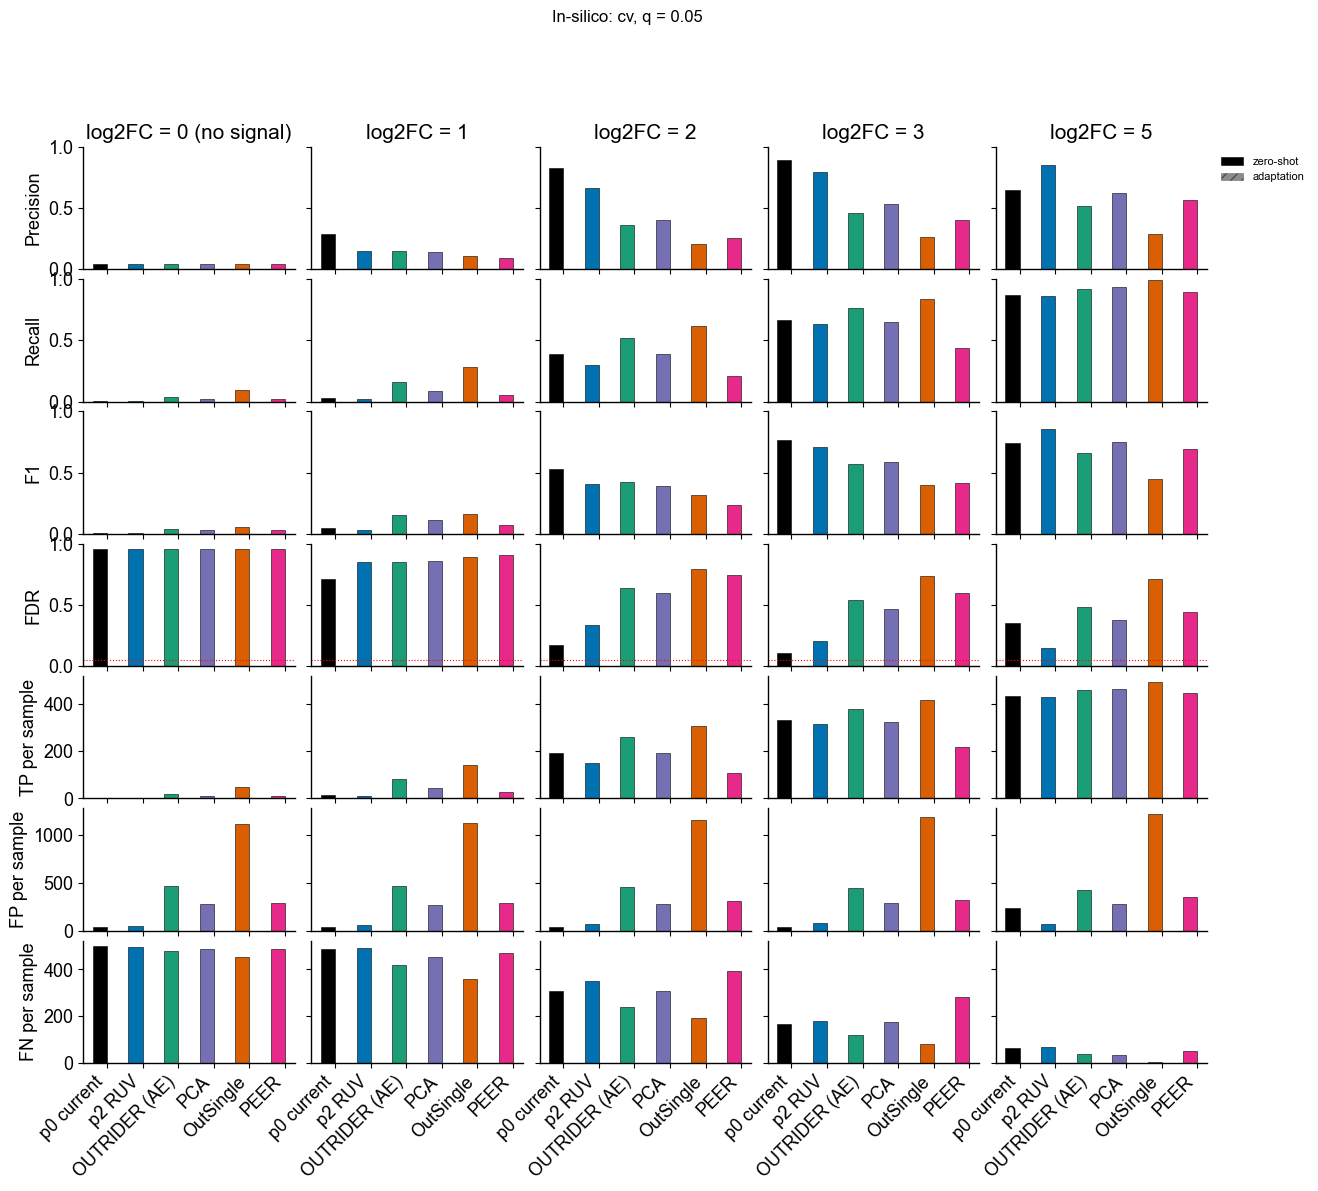

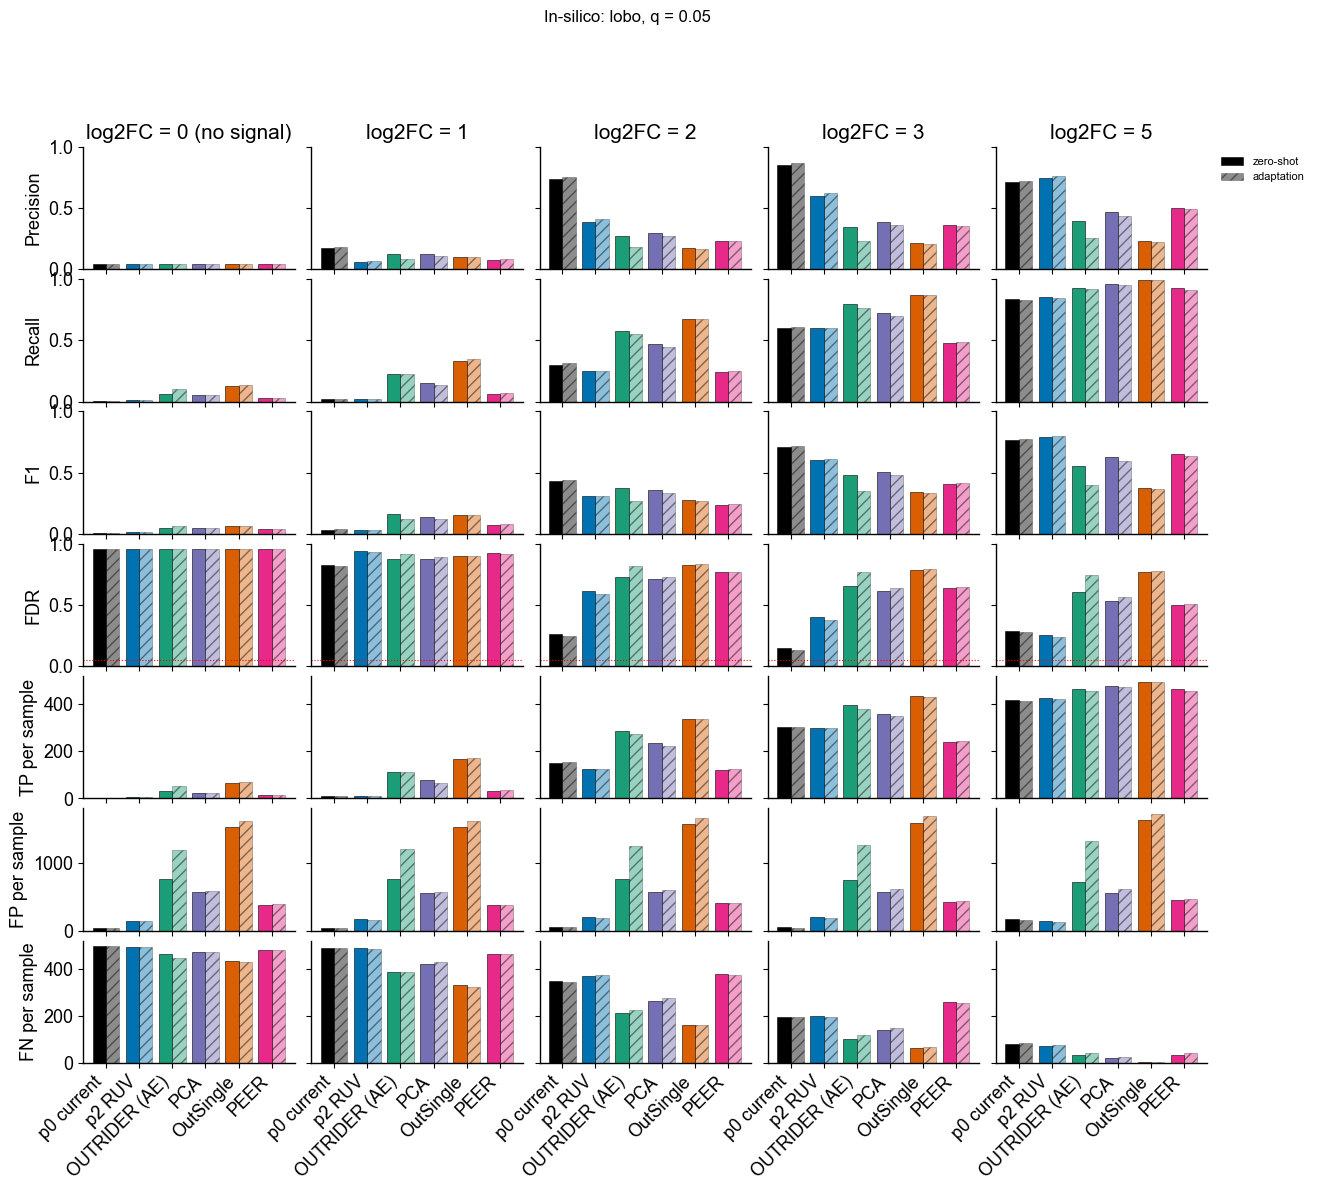

In [4]:
figure(ins, 'In-silico', 'insilico')

## Detection limit (nb3 design)

In [5]:
dl = summarize(pd.read_csv(config.DETECTION_LIMIT_CSV), unit=['batch', 'boot'])
dl.to_csv(config.RESULTS_DIR / 'summary_detection_limit.csv', index=False)
print(dl.groupby(['split', 'method'])['scenario'].unique().to_string())
tables(dl, 'detection limit')

split        method
insample_cv  p0                    [zero_shot]
             p2                    [zero_shot]
lobo         p0        [adaptation, zero_shot]
             p2        [adaptation, zero_shot]
===== detection limit | insample_cv | q=0.05
--- Precision


log2fc,0.0,1.0,2.0,3.0,5.0
scenario,zero_shot,zero_shot,zero_shot,zero_shot,zero_shot
method,,,,,
p0 current,0.022,0.501,0.956,0.965,0.812
p2 RUV,0.015,0.258,0.959,0.965,0.938


--- Recall


log2fc,0.0,1.0,2.0,3.0,5.0
scenario,zero_shot,zero_shot,zero_shot,zero_shot,zero_shot
method,,,,,
p0 current,0.0,0.002,0.189,0.43,0.692
p2 RUV,0.0,0.000,0.083,0.33,0.677


--- F1


...

log2fc            0.0                  1.0                  2.0                  3.0                  5.0          
scenario   adaptation zero_shot adaptation zero_shot adaptation zero_shot adaptation zero_shot adaptation zero_shot
method                                                                                                             
p0 current        2.0       2.2        4.0       4.2       78.3      74.9      192.5     193.5      322.0     326.6
p2 RUV            5.1       5.5        4.0       4.1       46.1      45.5      146.1     148.3      295.2     305.3

--- FP per sample


log2fc            0.0                  1.0                  2.0                  3.0                  5.0          
scenario   adaptation zero_shot adaptation zero_shot adaptation zero_shot adaptation zero_shot adaptation zero_shot
method                                                                                                             
p0 current      111.4     119.4      121.9     129.4      115.3     123.9      114.6     125.2      126.3     140.7
p2 RUV          204.4     228.9      202.3     225.3      204.9     233.0      211.7     234.5      162.1     196.7

--- FN per sample


log2fc            0.0                  1.0                  2.0                  3.0                  5.0          
scenario   adaptation zero_shot adaptation zero_shot adaptation zero_shot adaptation zero_shot adaptation zero_shot
method                                                                                                             
p0 current      498.0     497.8      496.0     495.8      421.7     425.1      307.5     306.5      178.0     173.4
p2 RUV          494.9     494.5      496.0     495.9      453.9     454.5      353.9     351.7      204.8     194.7

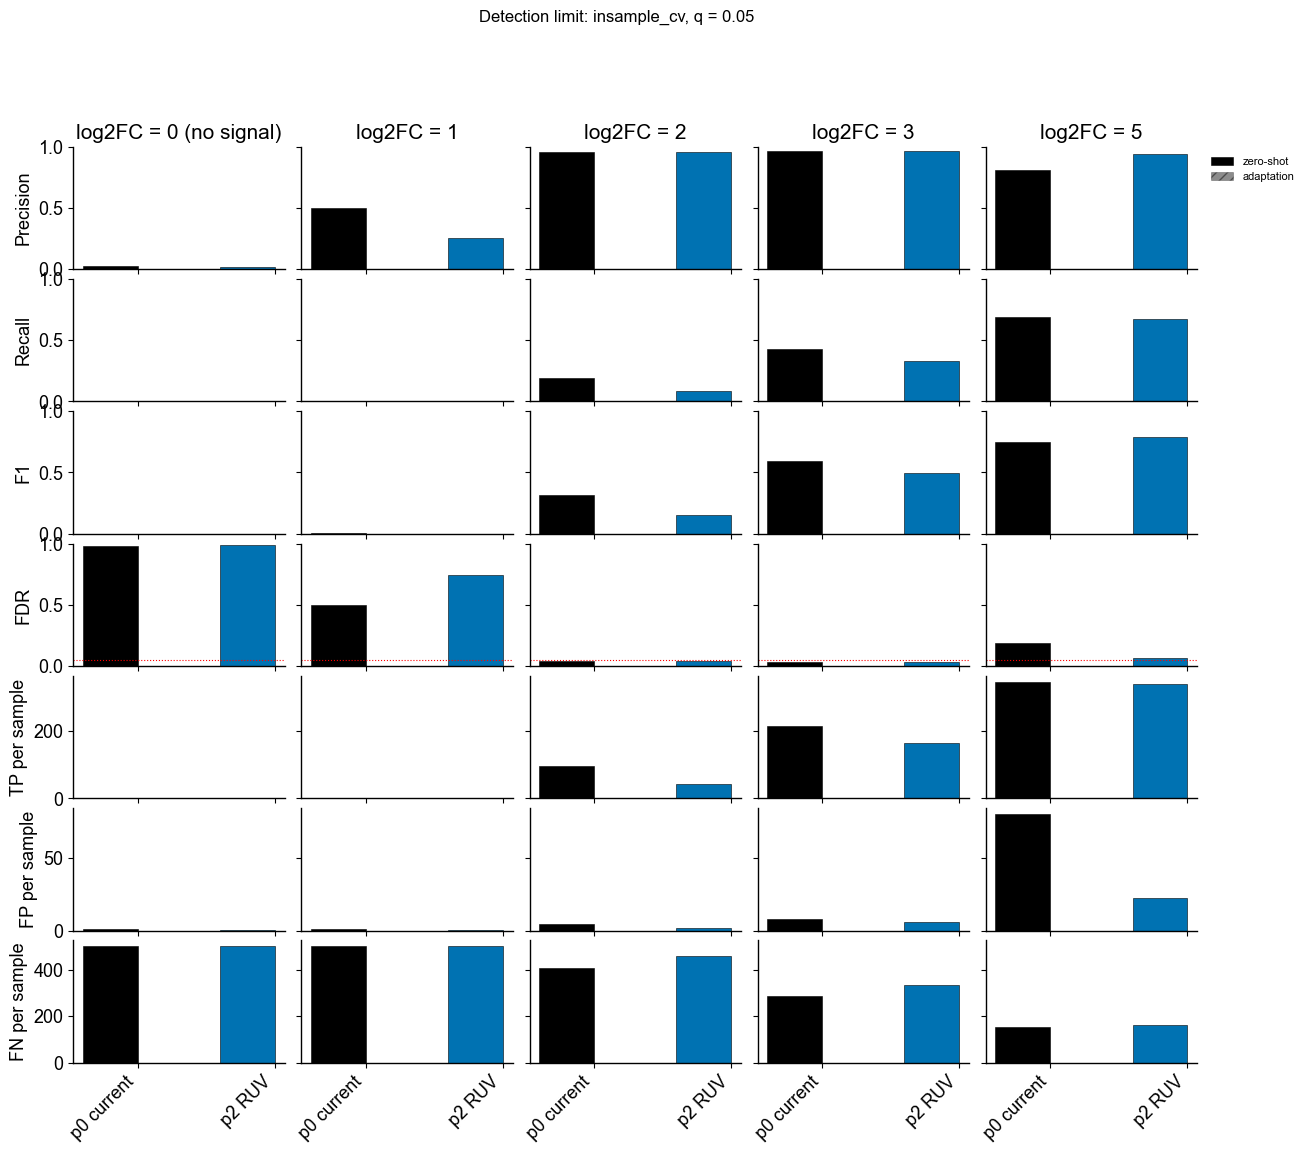

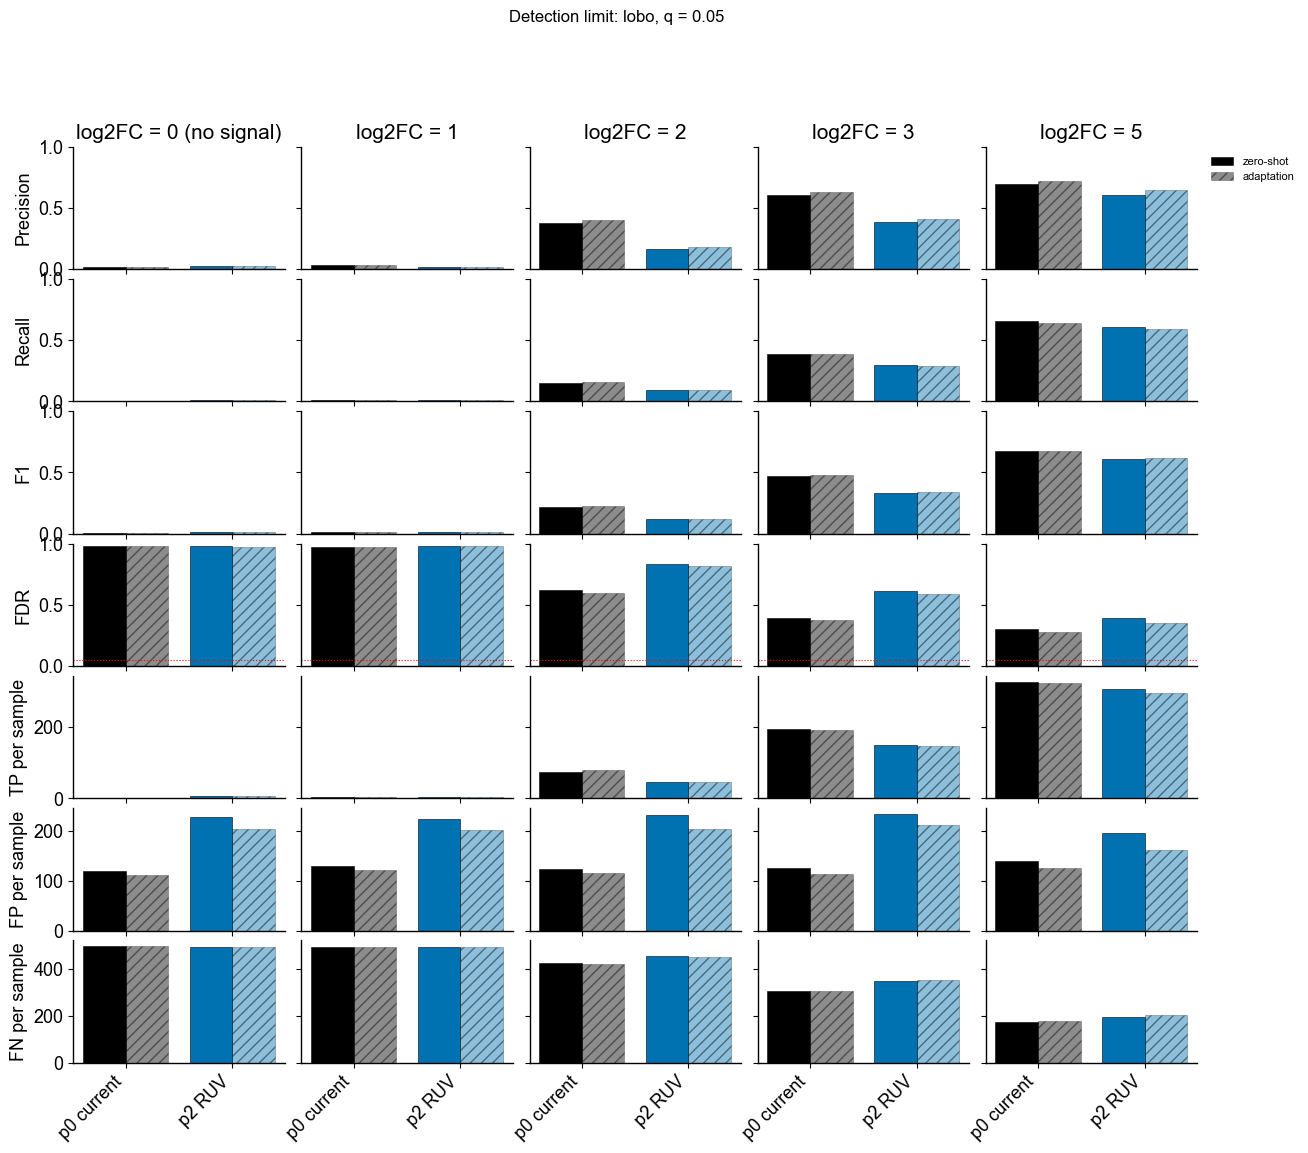

In [6]:
figure(dl, 'Detection limit', 'detection_limit')